In [1]:
import sys

sys.path.append("../src")
from configs.load_config import load_config
from data_processing.load import load_dataset
from models.build import build_model
from training.train import train_torch, sample_numpyro
import importlib
import training.evaluate as load_eval

importlib.reload(load_eval)
import matplotlib.pyplot as plt
from training.evaluate import (
    evaluate_model,
    evaluate_numpyro,
    evaluate_numpyro_on_train_set,
)
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import (
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_residuals,
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_first_layer_feature_posteriors,
    plot_bnn_weight_posteriors,
    plot_posterior_predictive_vs_likelihood,
    plot_stacked_hdi_intervals,
    plot_pit_histogram,
    extract_quantile_curves,
    evaluate_and_plot_qr_ensemble_medians,
    plot_posterior_predictive_family,
    plot_qr_hdi_prediction_simple,
    plot_qr_hdi_prediction_ensemble,
    plot_qr_hdi_prediction_ensemble_outline,
    plot_qr_hdi_prediction_ensemble_std,
    plot_qr_hdi_prediction_ensemble_std_bands,
    plot_bnn_gamma_combined,
)
import torch
import numpy as np
import numpyro
from data_processing.utils import (
    load_torch_model,
    load_checkpoint,
    save_scaler_params,
    approximate_qr_intervals,
)
import pandas as pd
from types import SimpleNamespace
from training.evaluate import crps_from_quantiles

In [2]:
# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_01_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-03-28_14-17-43_nowcast_ELSPOT_NO1"

# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_02_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-03-28_18-30-32_nowcast_ELSPOT_NO2"

# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_03_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-03-29_01-53-28_nowcast_ELSPOT_NO3"

# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_04_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-03-29_07-02-26_nowcast_ELSPOT_NO4"

# # Synthetic data
# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_01_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-03-25_10-23-37_nowcast_ELSPOT_NO1"

# model_cfg = load_config("../configs/model/torch_model_quantile_01.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "WindPowerQuantile_weighted_2026-04-09_10-26-25_nowcast_gen_ELSPOT_NO1"

model_cfg = load_config("../configs/model/torch_model_quantile_02.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "WindPowerQuantile_weighted_2026-04-09_10-26-57_nowcast_gen_ELSPOT_NO2"

# model_cfg = load_config("../configs/model/torch_model_quantile_03.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "WindPowerQuantile_weighted_2026-04-09_10-27-30_nowcast_gen_ELSPOT_NO3"

# model_cfg = load_config("../configs/model/torch_model_quantile_04.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "WindPowerQuantile_weighted_2026-04-09_10-28-02_nowcast_gen_ELSPOT_NO4"


data_cfg.dataset = "forecast"
data_cfg.ensemble = SimpleNamespace(members=None, variance=False)

In [3]:
data = load_dataset(data_cfg)

Loading forecast data for ELSPOT NO2, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
Loaded scaler parameters for ELSPOT NO2 and nowcast
  Saved at: 2026-04-07 15:24:08
  Split time: 2025-01-01 00:00:00+01:00
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 Index([      0,       1,       2,       3,       4,       5,       6,       7,
             8,       9,
       ...
       6874202, 6874203, 6874204, 6874205, 6874206, 6874207, 6874208, 6874209,
       6874210, 6874211],
      dtype='int64', length=6761520)
All parks operational from 2023-03-14 09:00:00
Before 2-day ahead filtering: 777087 rows
After 2-day ahead filtering: 287385 rows
Lead time range: 34.0h to 61.0h


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 217
Preprocessing done. X_train shape: (14828, 17, 15, 10)
Preprocessing done. X_test shape: (1884, 17, 15, 10)


In [4]:
Y_train = data["Y_train_gen"]

In [5]:
from data_processing.synthetic_data import synthetic_power_data

max_scaling = 1
# data["Y_train_gen"], _ = synthetic_power_data(data, "X_train")
# data["Y_test_gen"], _ = synthetic_power_data(data, "X_test")

# data["Y_train_gen"] /= max_scaling
# data["Y_test_gen"] /= max_scaling

In [6]:
data["Y_train_gen"].min(), data["Y_train_gen"].max()

(np.float32(0.21980898), np.float32(1349.1549))

In [7]:
model_name_for_title = "BNN" if model_cfg.backend == "numpyro" else "QRNN"

In [8]:
# if data_cfg.dataset == "nowcast":
#     save_scaler_params(
#         scaler_params=data["scaler_params"],
#         site_scaler_params=data["site_scaler_params"],
#         bid_zone=data_cfg.bid_zone,
#         split_time=pd.Timestamp("2025-01-01 00:00:00", tz="CET"),
#         dataset=data_cfg.dataset,
#         dir_path="../checkpoints",
#     )

In [9]:
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import plot_bnn_gamma_combined

In [10]:
if model_cfg.backend == "numpyro":
    checkpoint = load_checkpoint(file_name=file_name)
    model = build_model(checkpoint["model_cfg"], data)

    plot_bnn_gamma_combined(
        checkpoint,
        model,
        data,
        data_cfg,
        [0, 1080],
    )
    plt.show()
    # plt.savefig(
    #     f"../plots/ensemble_{data_cfg.dataset}_{model_cfg.data.bid_zone}_val.pdf"
    # )

In [11]:
median_list = []
hdi_list = []
percentile_list = []
y_pred_list = []

for member in range(15):

    if model_cfg.backend == "torch":
        if model_cfg.params.quantiles is None:
            if model_cfg.params.num_quantiles is not None:
                quantiles = torch.linspace(0, 1, model_cfg.params.num_quantiles)
            else:
                quantiles = torch.linspace(0, 1, 51)
        else:
            quantiles = torch.tensor(model_cfg.params.quantiles)

        model, checkpoint = load_torch_model(file_name=file_name, quantiles=quantiles)

        metrics, y_pred = evaluate_model(
            model=model,
            data=data,
            quantiles=quantiles,
            model_cfg=checkpoint["model_cfg"],
            member=member,
        )
        # TODO: don't use HDI for QR
        hdis, _, _, _ = approximate_qr_intervals(
            Y_pred=y_pred,
            taus=quantiles,
            cred_mass=0.95,
        )

        # Extract curves, TODO: not 95% CI!!
        median, lower, upper = extract_quantile_curves(
            Y_pred_quantiles=y_pred,
            quantiles=quantiles,
            median_q=0.5,
            lower_q=0.025,
            upper_q=0.975,
        )
        percentiles = np.stack([lower, upper], axis=1)

        median_list.append(median)
        hdi_list.append(hdis.T)
        percentile_list.append(percentiles)
        y_pred_list.append(y_pred)

    elif model_cfg.backend == "numpyro":

        checkpoint = load_checkpoint(file_name=file_name)
        model = build_model(checkpoint["model_cfg"], data)
        samples = checkpoint["samples"]
        metrics, y_pred, predictive, median, percentiles, hdis = evaluate_numpyro(
            model=model,
            samples=checkpoint["samples"],
            rng_key_predict=checkpoint["rng_key_predict"],
            data=data,
            model_cfg=checkpoint["model_cfg"],
            member=member,
            max_scaling=max_scaling,
        )
        if member == 0:
            print(metrics)

        median_list.append(median)
        hdi_list.append(hdis)
        percentile_list.append(percentiles)
        y_pred_list.append(y_pred)

    # print(metrics)

    if data_cfg.dataset == "nowcast":
        # validate on nowcast, only one loop, otherwise validation on all ensemble members
        print("break")
        break


# assert checkpoint["model_cfg"] == model_cfg

Loaded model: WindPowerQuantile_weighted_2026-04-09_10-26-57_nowcast_gen_ELSPOT_NO2.pt
  Model class: WindPowerQuantile_weighted
Choose member 0
Choose member 0
     rmse_median_train: tensor(173.8136)

   crps_train: tensor(93.2109)

   coverage_025_975_train: tensor(0.8058)

   coverage_0_50_train: tensor(0.4184)
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-26-57_nowcast_gen_ELSPOT_NO2.pt
  Model class: WindPowerQuantile_weighted
Choose member 1
Choose member 1
     rmse_median_train: tensor(217.7254)

   crps_train: tensor(123.1334)

   coverage_025_975_train: tensor(0.7123)

   coverage_0_50_train: tensor(0.3798)
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-26-57_nowcast_gen_ELSPOT_NO2.pt
  Model class: WindPowerQuantile_weighted
Choose member 2
Choose member 2
     rmse_median_train: tensor(221.1187)

   crps_train: tensor(122.8264)

   coverage_025_975_train: tensor(0.7217)

   coverage_0_50_train: tensor(0.3805)
Loaded model: WindPowerQuantile_weighted_2026-0

In [12]:
median_df = pd.DataFrame(
    np.column_stack(median_list),
    columns=[f"median_{i}" for i in range(len(median_list))],
)

hdi_dict = {}

for i, arr in enumerate(hdi_list):
    hdi_dict[f"hdi_lower_{i}"] = arr[0]
    hdi_dict[f"hdi_upper_{i}"] = arr[1]

hdi_df = pd.DataFrame(hdi_dict)

ensemble_results = pd.concat([median_df, hdi_df], axis=1)

median_cols = ensemble_results.filter(regex=r"^median_").columns
hdi_lower_cols = ensemble_results.filter(regex=r"^hdi_lower_").columns
hdi_upper_cols = ensemble_results.filter(regex=r"^hdi_upper_").columns

ensemble_results["mean_median"] = ensemble_results[median_cols].mean(axis=1)
ensemble_results["std_median"] = ensemble_results[median_cols].std(axis=1)
ensemble_results["mean_hdi_lower"] = ensemble_results[hdi_lower_cols].mean(axis=1)
ensemble_results["std_hdi_lower"] = ensemble_results[hdi_lower_cols].std(axis=1)
ensemble_results["mean_hdi_upper"] = ensemble_results[hdi_upper_cols].mean(axis=1)
ensemble_results["std_hdi_upper"] = ensemble_results[hdi_upper_cols].std(axis=1)

In [13]:
# import numpy as np

# for k, v in samples.items():
#     v = np.asarray(v)
#     print(
#         f"{k:20s} shape={v.shape} finite={np.isfinite(v).all()} "
#         f"min={np.nanmin(v):.3g} max={np.nanmax(v):.3g}"
#     )

In [14]:
# import numpy as np
# import arviz as az

# posterior = {k: np.asarray(v)[None, ...] for k, v in samples.items()}  # (1, 100, ...)

# idata = az.from_dict(posterior=posterior)
# az.plot_trace(idata, var_names=["b1", "b2", "b3mu", "b3k"])

In [15]:
# import matplotlib.pyplot as plt

# i = 0
# plt.plot(samples["mu"][:, i])
# plt.title(f"Trace mu[{i}]")
# plt.show()

### Plots


In [16]:
if model_cfg.backend == "numpyro":
    X_test = data["X_test"]
    if len(X_test.shape) == 4:
        X_test = X_test[:, :, 0]
    graph = numpyro.render_model(
        model,
        model_args=(X_test,),
    )
    graph

In [17]:
try:
    graph
except:
    pass

In [18]:
import importlib
import training.plot as load_plot

importlib.reload(load_plot)

from training.plot import (
    plot_qr_hdi_prediction,
    plot_qr_hdi_prediction_ensemble,
    plot_qr_hdi_prediction_ensemble_outline,
    plot_qr_hdi_prediction_ensemble_std,
    plot_bnn_gamma_combined,
    plot_qr_hdi_prediction_ensemble_combined,
    plot_qr_prediction_ensemble,
)

In [19]:
if model_cfg.backend == "numpyro":
    (
        metrics_train,
        y_pred_train,
        predictive_train,
        median_train,
        percentiles_train,
        hdis_train,
    ) = evaluate_numpyro_on_train_set(
        model, checkpoint["samples"], checkpoint["rng_key_predict"], data, model_cfg
    )
    # Plot
    fig, axes = plot_qr_hdi_prediction(
        Y_true=data["Y_train_gen"],
        conf_interval=hdis_train.T,  # hdi_list[0].T,
        medians=median_train,  # median_list[0],
        plot_interval=[100, 1100],
        title=f"BNN {model_cfg.data.bid_zone} {data_cfg.dataset} train",
        timestamps=data["X_train_timestamps"],
    )
    # plt.savefig(
    #     f"../plots/ensemble_{model_name_for_title}_{data_cfg.dataset}_{model_cfg.data.bid_zone}_train.pdf"
    # )
    plt.show()

In [20]:
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import (
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_residuals,
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_first_layer_feature_posteriors,
    plot_bnn_weight_posteriors,
    plot_posterior_predictive_vs_likelihood,
    plot_stacked_hdi_intervals,
    plot_pit_histogram,
    extract_quantile_curves,
    evaluate_and_plot_qr_ensemble_medians,
    plot_posterior_predictive_family,
    plot_qr_hdi_prediction_simple,
    plot_qr_hdi_prediction_ensemble,
    plot_qr_hdi_prediction_ensemble_outline,
    plot_qr_hdi_prediction_ensemble_std,
    plot_qr_hdi_prediction_ensemble_std_bands,
    plot_bnn_gamma_combined,
    plot_qr_prediction_ensemble,
    plot_pit_histogram,
)

In [21]:
# plot_qr_hdi_prediction_simple(
#     Y_true=data["Y_train_gen"],
#     conf_interval=hdis_train.T,  # hdi_list[0].T,
#     medians=median_train,  # median_list[0],
#     plot_interval=[100, 1100],
#     title=f"BNN {model_cfg.data.bid_zone} {data_cfg.dataset} train",
#     timestamps=data["X_train_timestamps"],
# )
# # plt.savefig(
# #     f"../plots/{model_name_for_title}_{data_cfg.dataset}_{model_cfg.data.bid_zone}_train.pdf"
# # )
# plt.show()

In [22]:
# plot_qr_hdi_prediction_simple(
#     Y_true=data["Y_test_gen"],
#     conf_interval=hdis.T,  # hdi_list[0].T,
#     medians=median,  # median_list[0],
#     plot_interval=[100, 1100],
#     title=f"BNN synthetic target {model_cfg.data.bid_zone} {data_cfg.dataset} val",
#     timestamps=data["X_test_timestamps"],
# )
# plt.savefig(
#     f"../plots/synthetic_{model_name_for_title}_{data_cfg.dataset}_{model_cfg.data.bid_zone}_val.pdf"
# )
# plt.show()

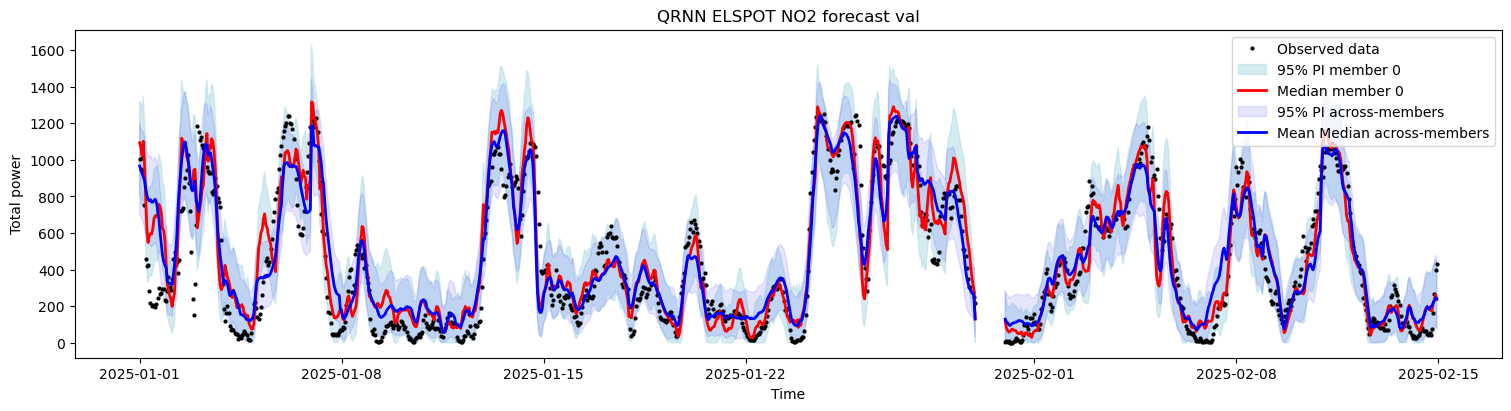

In [23]:
if model_cfg.backend == "torch":
    plot_qr_prediction_ensemble(
        Y_true=data["Y_test_gen"],
        Y_pred=y_pred_list,
        plot_interval=[0, 1080],
        title=f"{model_name_for_title} {model_cfg.data.bid_zone} {data_cfg.dataset} val",
        timestamps=data["X_test_timestamps"],
    )
    plt.savefig(
        f"../plots/ensemble_{data_cfg.dataset}_{model_name_for_title}_{model_cfg.data.bid_zone}_val.pdf"
    )

In [24]:
timestamps = pd.date_range(
    data["X_test_timestamps"][0], data["X_test_timestamps"][-1], freq="h"
)

In [25]:
df = pd.DataFrame(
    np.stack(
        [data["Y_test_gen"], hdi_list[0].T[:, 0], hdi_list[0].T[:, 1], median_list[0]]
    ).T,
    index=data["X_test_timestamps"],
    columns=["Y_true", "hdi_lower", "hdi_upper", "median"],
)
full_index = pd.date_range(df.index.min(), df.index.max(), freq="h")

# Reindex and fill missing timestamps with NaN
df_full = df.reindex(full_index)

In [26]:
data["feature_cols"]

['air_pressure_at_sea_level',
 'air_temperature_2m',
 'hour_x',
 'hour_y',
 'relative_humidity_2m',
 'wind_direction_10m_x',
 'wind_direction_10m_y',
 'wind_speed_10m',
 'wind_speed_10m+1',
 'wind_speed_10m-1']

In [27]:
import importlib
import training.plot as load_plot

importlib.reload(load_plot)

from training.plot import (
    plot_qr_hdi_prediction,
    plot_qr_hdi_prediction_ensemble,
    plot_qr_hdi_prediction_ensemble_outline,
    plot_qr_hdi_prediction_ensemble_std,
)

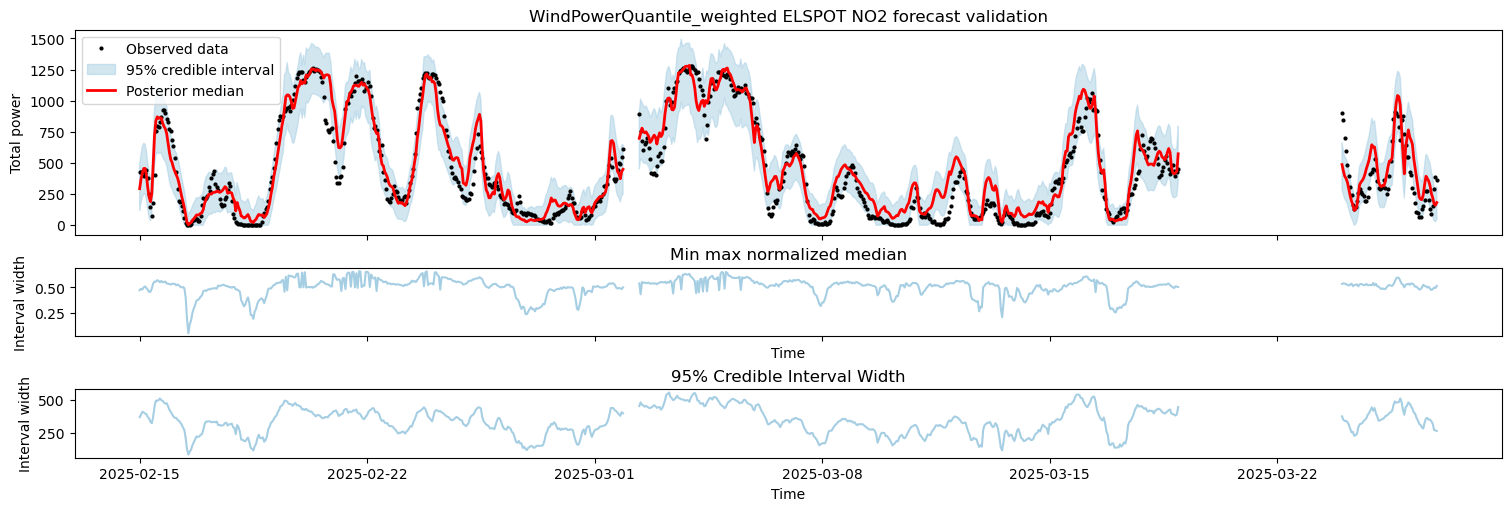

In [28]:
# Plot

fig, axes = plot_qr_hdi_prediction(
    Y_true=data["Y_test_gen"] * max_scaling,
    conf_interval=hdi_list[0].T,  # percentile_list[0]
    medians=median_list[0],
    plot_interval=[1080, 1080 * 2],
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} validation",
    timestamps=data["X_test_timestamps"],
)
# plt.savefig(
#     f"../plots/ensemble_{data_cfg.dataset}_{model_name_for_title}_{model_cfg.data.bid_zone}_val_member0.pdf"
# )
plt.show()

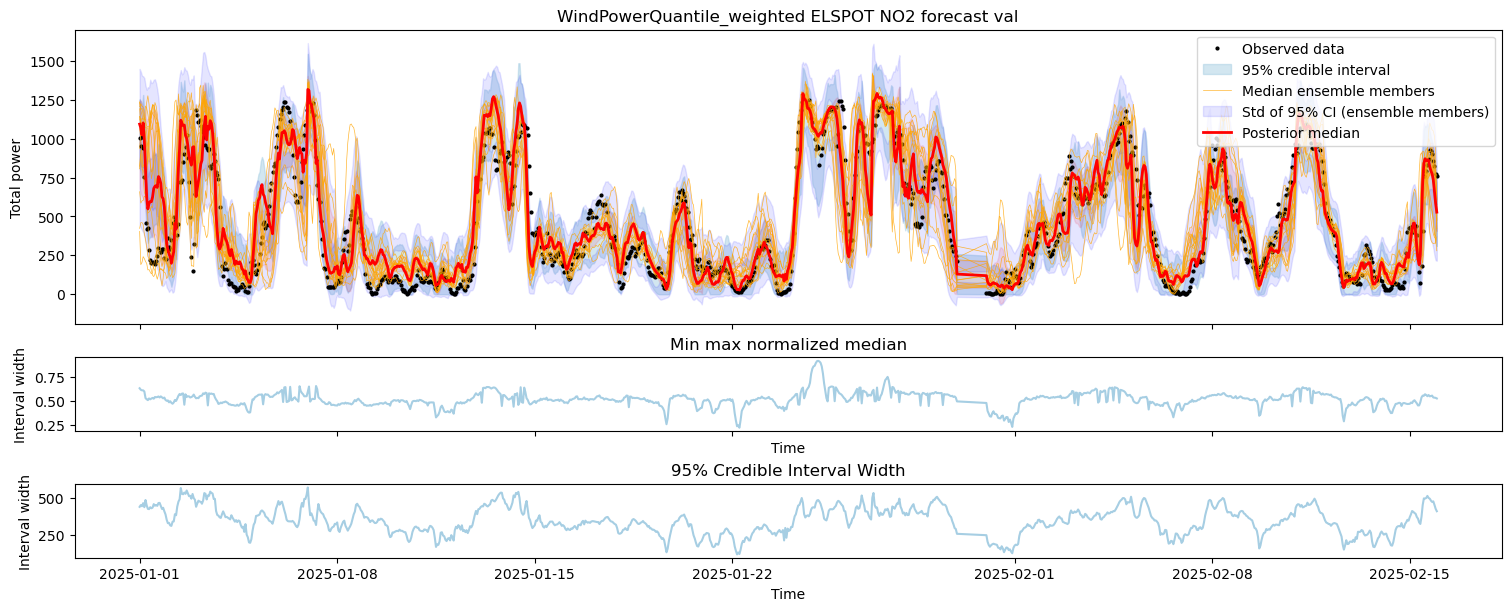

In [29]:
fig, axes = plot_qr_hdi_prediction_ensemble(
    Y_true=data["Y_test_gen"] * max_scaling,
    ensemble_results=ensemble_results,
    plot_interval=[0, 1080],
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} val",
    timestamps=data["X_test_timestamps"],
)
plt.show()

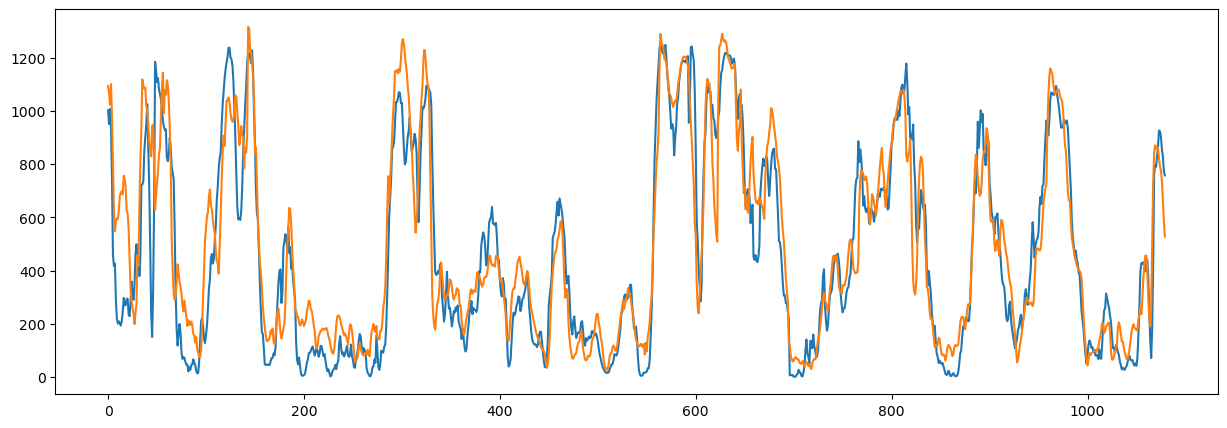

In [30]:
plt.figure(figsize=(15, 5))
plt.plot(data["Y_test_gen"][:1080] * max_scaling)
plt.plot(median_list[0][:1080])

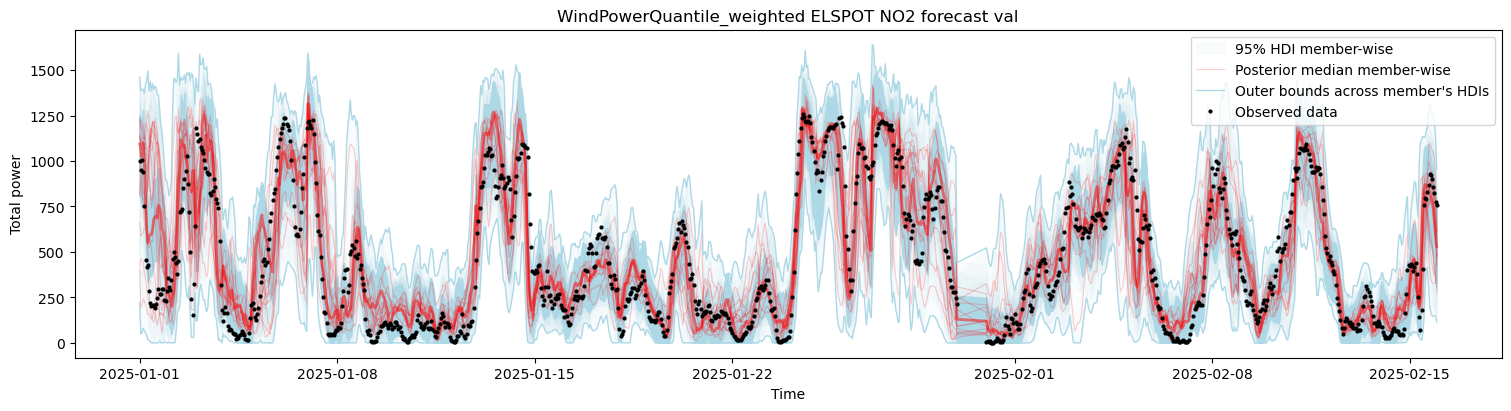

In [31]:
fig, axes = plot_qr_hdi_prediction_ensemble_outline(
    Y_true=data["Y_test_gen"],
    ensemble_results=ensemble_results,
    plot_interval=[0, 1080],
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} val",
    timestamps=data["X_test_timestamps"],
)
plt.show()

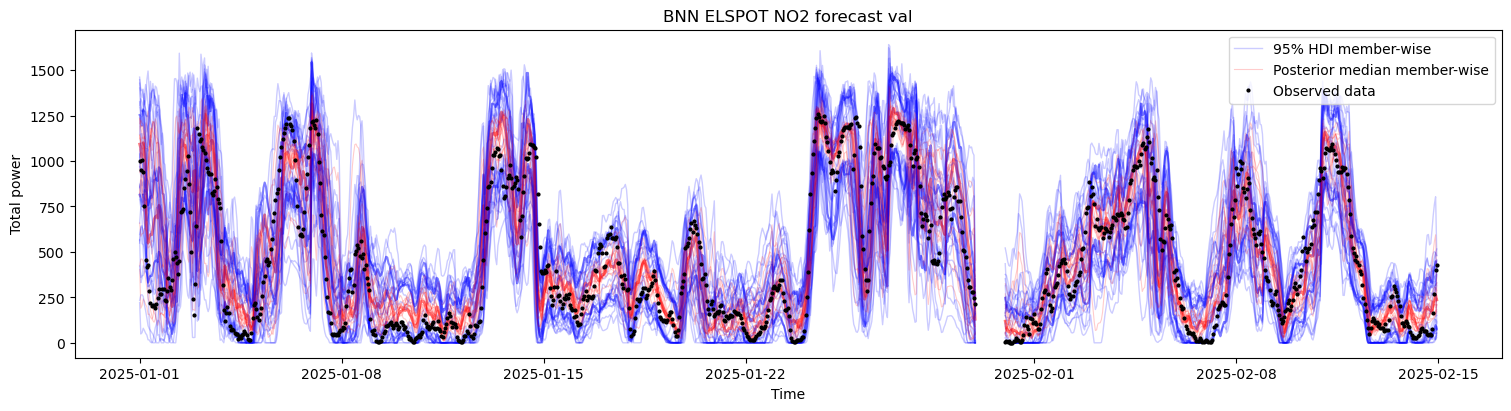

In [32]:
fig, axes = plot_qr_hdi_prediction_ensemble_std(
    Y_true=data["Y_test_gen"],
    ensemble_results=ensemble_results,
    plot_interval=[0, 1080],
    title=f"BNN {model_cfg.data.bid_zone} {data_cfg.dataset} val",
    timestamps=data["X_test_timestamps"],
)
plt.savefig(
    f"../plots/ensemble_lines_{data_cfg.dataset}_{model_name_for_title}_{model_cfg.data.bid_zone}_val.pdf"
)

In [33]:
model_cfg

namespace(backend='torch',
          name='WindPowerQuantile_weighted',
          experiment_name='QRNN NO2',
          data=namespace(path='../configs/data/nowcast02.yaml',
                         bid_zone='ELSPOT NO2'),
          params=namespace(quantiles=None, num_quantiles=41, target='gen'),
          training=namespace(optimizer='adam',
                             lr=0.05,
                             num_steps=5000,
                             loss='quantile_loss_weighted'),
          evaluation=namespace(dates=None, path=None))

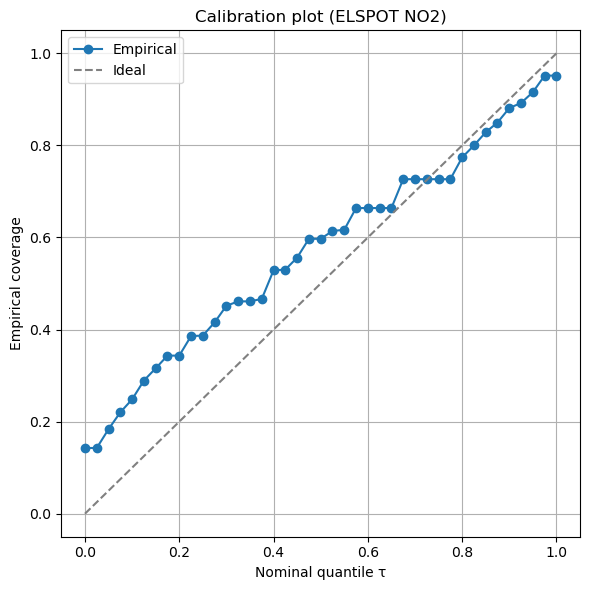

In [34]:
# y_pred: (S, N)
stacked_list = np.concatenate(y_pred_list, axis=0)

quantiles = torch.linspace(0, 1, 41)

if model_cfg.backend == "torch" and model_cfg.params.quantiles is None:
    if model_cfg.params.num_quantiles is not None:
        quantiles = torch.linspace(0, 1, model_cfg.params.num_quantiles)
    else:
        quantiles = torch.linspace(0, 1, 51)

emp_cov = plot_quantile_calibration(
    Y_pred_quantiles=(
        # np.quantile(y_pred_list[0], quantiles, axis=0).T # only member 0
        np.quantile(stacked_list, quantiles, axis=0).T  # across all members
        if model_cfg.backend == "numpyro"
        else torch.mean(torch.stack(y_pred_list, dim=0), dim=0)  # across all members
        # else y_pred_list[0] # only member 0
    ),
    Y_true=(
        data["Y_test_gen"] * max_scaling
        if model_cfg.params.target == "gen"
        else data["Y_test_cf"]
    ),
    quantiles=quantiles,
    bz=model_cfg.data.bid_zone,
)
plt.savefig(
    f"../plots/calibration_{model_name_for_title}_{data_cfg.dataset}_{model_cfg.data.bid_zone}_val.pdf"
)

In [35]:
# Metrics across ensemble members (not just member 0)
import properscoring as ps
import arviz as az

if data_cfg.dataset == "forecast" and model_cfg.backend == "numpyro":
    stacked_preds = np.concatenate(y_pred_list, axis=0)
    percentiles_all = np.percentile(stacked_preds, [2.5, 97.5], axis=0)
    # TODO: hier wenden mit HDIs verwendet!!
    hdis_all = az.hdi(np.expand_dims(stacked_preds, axis=0), hdi_prob=0.95).T

    results = {}
    Y_test = data["Y_test_gen"]
    results["rmse_median"] = np.sqrt(
        np.mean((np.median(stacked_preds, axis=0) - Y_test) ** 2)
    )
    # Coverage mit HDIs
    results["coverage_025_975"] = (
        (Y_test >= hdis_all[0]) & (Y_test <= hdis_all[1])
    ).mean()
    results["coverage_0_50"] = (Y_test <= np.median(stacked_preds)).mean()
    results["crps"] = ps.crps_ensemble(Y_test, stacked_preds, axis=0).mean()

    print(results)

In [36]:
# Metrics across ensemble members (not just member 0)

if data_cfg.dataset == "forecast" and model_cfg.backend == "torch":
    print(quantiles)

    ensemble = torch.stack(y_pred_list, dim=0)  # [15, N, Q]
    ensemble_mean = torch.mean(ensemble, dim=0)  # [N, Q]

    median_idx = torch.argmin(torch.abs(quantiles - 0.5)).item()
    lower_idx = torch.argmin(torch.abs(quantiles - 0.025)).item()
    upper_idx = torch.argmin(torch.abs(quantiles - 0.975)).item()

    y_pred_median = ensemble_mean[:, median_idx]
    y_pred_lower = ensemble_mean[:, lower_idx]
    y_pred_upper = ensemble_mean[:, upper_idx]

    Y_test = data["Y_test_gen"]
    if not isinstance(Y_test, torch.Tensor):
        Y_test = torch.tensor(Y_test, dtype=ensemble_mean.dtype)

    results = {}
    results["rmse_median"] = torch.sqrt(torch.mean((y_pred_median - Y_test) ** 2))
    # Coverage with learned quantile values
    results["coverage_025_975"] = (
        ((Y_test >= y_pred_lower) & (Y_test <= y_pred_upper)).float().mean()
    )
    results["coverage_0_50"] = (Y_test <= y_pred_median).float().mean()

    results["crps"] = crps_from_quantiles(
        Y_test,
        ensemble_mean,
        quantiles,
    )

    print(results)

tensor([0.0000, 0.0250, 0.0500, 0.0750, 0.1000, 0.1250, 0.1500, 0.1750, 0.2000,
        0.2250, 0.2500, 0.2750, 0.3000, 0.3250, 0.3500, 0.3750, 0.4000, 0.4250,
        0.4500, 0.4750, 0.5000, 0.5250, 0.5500, 0.5750, 0.6000, 0.6250, 0.6500,
        0.6750, 0.7000, 0.7250, 0.7500, 0.7750, 0.8000, 0.8250, 0.8500, 0.8750,
        0.9000, 0.9250, 0.9500, 0.9750, 1.0000])
{'rmse_median': tensor(141.9716), 'coverage_025_975': tensor(0.8089), 'coverage_0_50': tensor(0.5971), 'crps': tensor(77.5647)}


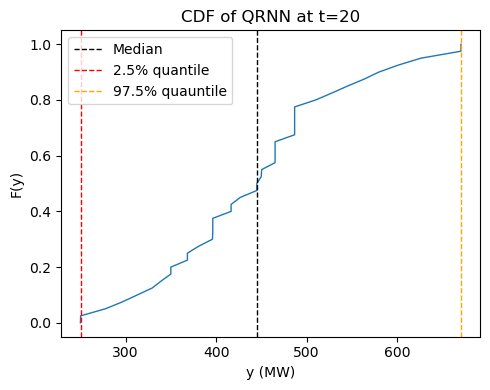

In [37]:
if model_cfg.backend == "torch":
    t = 20

    ensemble = torch.stack(y_pred_list, dim=0)  # [15, N, Q]
    ensemble_mean = torch.mean(ensemble, dim=0)  # [N, Q]

    if model_cfg.params.quantiles is None:
        if model_cfg.params.num_quantiles is not None:
            quantiles = torch.linspace(0, 1, model_cfg.params.num_quantiles)
        else:
            quantiles = torch.linspace(0, 1, 51)
    else:
        quantiles = torch.tensor(model_cfg.params.quantiles)

    q5_idx = torch.argmin(torch.abs(quantiles - 0.5)).item()
    q025_idx = torch.argmin(torch.abs(quantiles - 0.025)).item()
    q975_idx = torch.argmin(torch.abs(quantiles - 0.975)).item()

    plt.figure(figsize=(5, 4))
    plt.plot(ensemble_mean[t], quantiles, lw=1)
    plt.axvline(
        ensemble_mean[t][q5_idx], color="black", lw=1, linestyle="--", label="Median"
    )
    plt.axvline(
        ensemble_mean[t][q025_idx],
        color="red",
        lw=1,
        linestyle="--",
        label="2.5% quantile",
    )
    plt.axvline(
        ensemble_mean[t][q975_idx],
        color="orange",
        lw=1,
        linestyle="--",
        label="97.5% quauntile",
    )
    plt.xlabel("y (MW)")
    plt.ylabel("F(y)")
    plt.title(f"CDF of QRNN at t={t}")
    plt.legend()
    plt.tight_layout()
    plt.show()

skew: 0.14568287


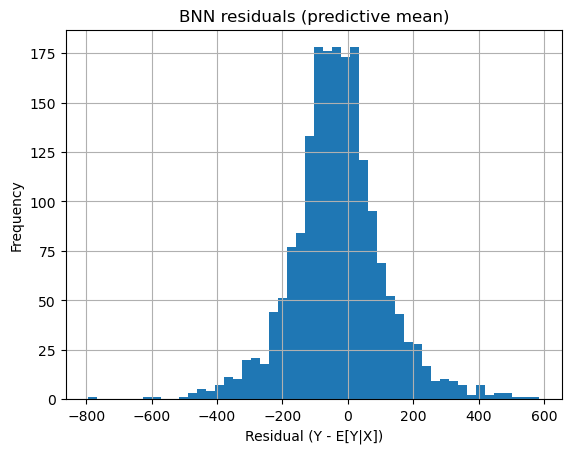

array([ -90.944885, -117.30884 ,  -16.126343, ...,  116.01558 ,
        225.57178 ,  178.55957 ], shape=(1884,), dtype=float32)

In [38]:
plot_residuals(
    median_list[0] * max_scaling,
    data["Y_test_gen"],
)

In [39]:
if model_cfg.backend == "numpyro":
    plot_first_layer_feature_posteriors(checkpoint["samples"], data)

In [40]:
if model_cfg.backend == "numpyro":
    plot_bnn_weight_posteriors(checkpoint["samples"])

In [41]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_vs_likelihood(
        predictive=predictive,
        model_name=model_cfg.name,
        t=20,
    )
# TODO: mean (rot) macht nicht so richtig Sinn, wird von verschiedenen Gammas gesampelt (mixture)

In [42]:
Y_test.shape

torch.Size([1884])

In [43]:
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import plot_posterior_predictive_family_simple

In [44]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_family_simple(
        stacked_preds, model_cfg, data, t=20, hdi=hdis_all.T
    )

    # Epistemic uncertainty on the left: different outputs for the different model realizations
    # Aleatoric uncertainty on the right: different gamma distribution, each realization's variance informs about it's aleatoric uncertainty
    # TODO: does it make sense to take the mean of the parameters, so say something about its average aleatoric uncertainty? -> NO

In [45]:
from scipy.stats import gaussian_kde
import numpy as np
import matplotlib.pyplot as plt

if model_cfg.backend == "numpyro":
    t = 20
    y_samples = np.asarray(predictive["Y"][:, t])

    import numpy as np
    import matplotlib.pyplot as plt

    def compute_ecdf(samples):
        samples = np.sort(samples)
        n = len(samples)
        y = np.arange(1, n + 1) / n
        return samples, y

    x_ecdf, F_ecdf = compute_ecdf(y_samples)

    plt.figure(figsize=(5, 4))
    plt.step(x_ecdf, F_ecdf, where="post", label="BNN empirical CDF")

    # optional: true value
    y_true = data["Y_test_gen"][t]
    plt.axvline(y_true, color="red", linestyle="--", label="Observed y")

    plt.xlabel("y")
    plt.ylabel("F(y)")
    plt.title(f"BNN predictive CDF (t={t})")
    plt.legend()
    plt.show()

In [46]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_family(
        predictive, model_cfg, data, t=300, hdi=percentiles
    )

    # Epistemic uncertainty on the left: different outputs for the different model realizations
    # Aleatoric uncertainty on the right: different gamma distribution, each realization's variance informs about it's aleatoric uncertainty
    # TODO: does it make sense to take the mean of the parameters, so say something about its average aleatoric uncertainty? -> NO

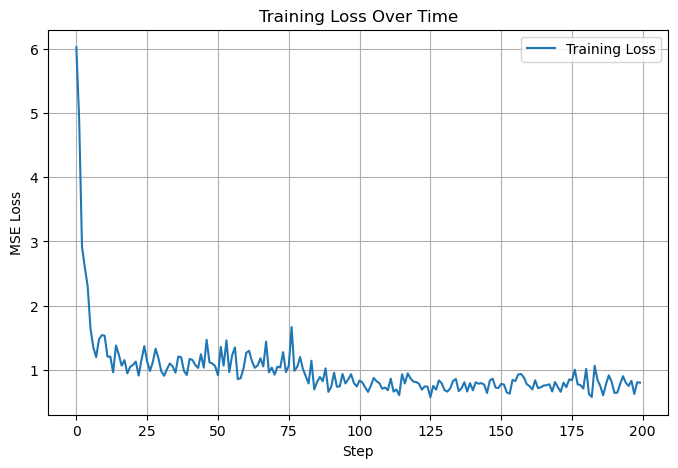

In [47]:
if model_cfg.backend == "torch":
    plt.figure(figsize=(8, 5))
    plt.plot(checkpoint["losses"][::25], label="Training Loss")
    plt.xlabel("Step")
    plt.ylabel("MSE Loss")
    plt.title("Training Loss Over Time")
    plt.legend()
    plt.grid(True)
    plt.show()

In [48]:
if model_cfg.backend == "numpyro":
    plot_stacked_hdi_intervals(
        preds=y_pred_list[0],
        Y_true=data["Y_test_gen"],
        n_plot=200,
        timestamps=data["X_test_timestamps"],
    )

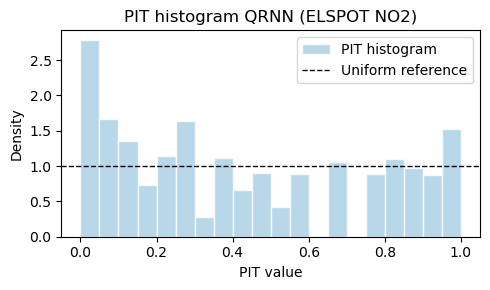

In [49]:
pits = plot_pit_histogram(
    preds=stacked_list, Y_true=data["Y_test_gen"], model_cfg=model_cfg, bins=20
)
plt.savefig(
    f"../plots/PIT_{model_name_for_title}_{data_cfg.dataset}_{model_cfg.data.bid_zone}_val.pdf"
)

In [50]:
stacked_list.shape[1]

41

In [51]:
# import numpy as np
# import matplotlib.pyplot as plt
# from data_processing.utils import QuantileDistribution


# def compute_pit_from_quantiles(preds, y_true, quantiles):
#     """
#     preds [N, Q]
#     y_true: [N]
#     quantiles: [Q]
#     """
#     preds = np.asarray(preds)
#     y_true = np.asarray(y_true)
#     quantiles = np.asarray(quantiles)

#     pits = np.empty(len(y_true))

#     for t in range(len(y_true)):
#         pits[t] = QuantileDistribution(quantiles, preds[t]).cdf(y_true[t])

#     return pits


# ensemble = torch.stack(y_pred_list, dim=0)  # [15, N, Q]
# ensemble_mean = torch.mean(ensemble, dim=0)  # [N, Q]
# pits = compute_pit_from_quantiles(ensemble_mean, data["Y_test_gen"], quantiles)
# # Plot histogram
# plt.figure(figsize=(5, 3))
# plt.hist(
#     pits,
#     bins=20,
#     range=(0, 1),
#     density=True,
#     alpha=0.8,
#     color="#A6CEE3",
#     edgecolor="white",
#     label=f"PIT histogram (ELSPOT NO1)",
# )
# plt.axhline(
#     1.0,
#     color="k",
#     ls="--",
#     lw=1,
#     label="Uniform reference",
# )

# plt.xlabel("PIT value")
# plt.ylabel("Density")
# plt.title("PIT histogram")
# plt.legend()
# plt.show()

Member 0 RMSE: 144.5287
Member 1 RMSE: 207.1001
Member 2 RMSE: 176.6631
Member 3 RMSE: 200.3581
Member 4 RMSE: 206.7139
Member 5 RMSE: 208.4081
Member 6 RMSE: 173.5915
Member 7 RMSE: 207.6866
Member 8 RMSE: 196.1767
Member 9 RMSE: 207.3475
Member 10 RMSE: 186.3039
Member 11 RMSE: 201.2390
Member 12 RMSE: 190.5818
Member 13 RMSE: 194.1852
Member 14 RMSE: 186.6114

Average RMSE: 192.4997


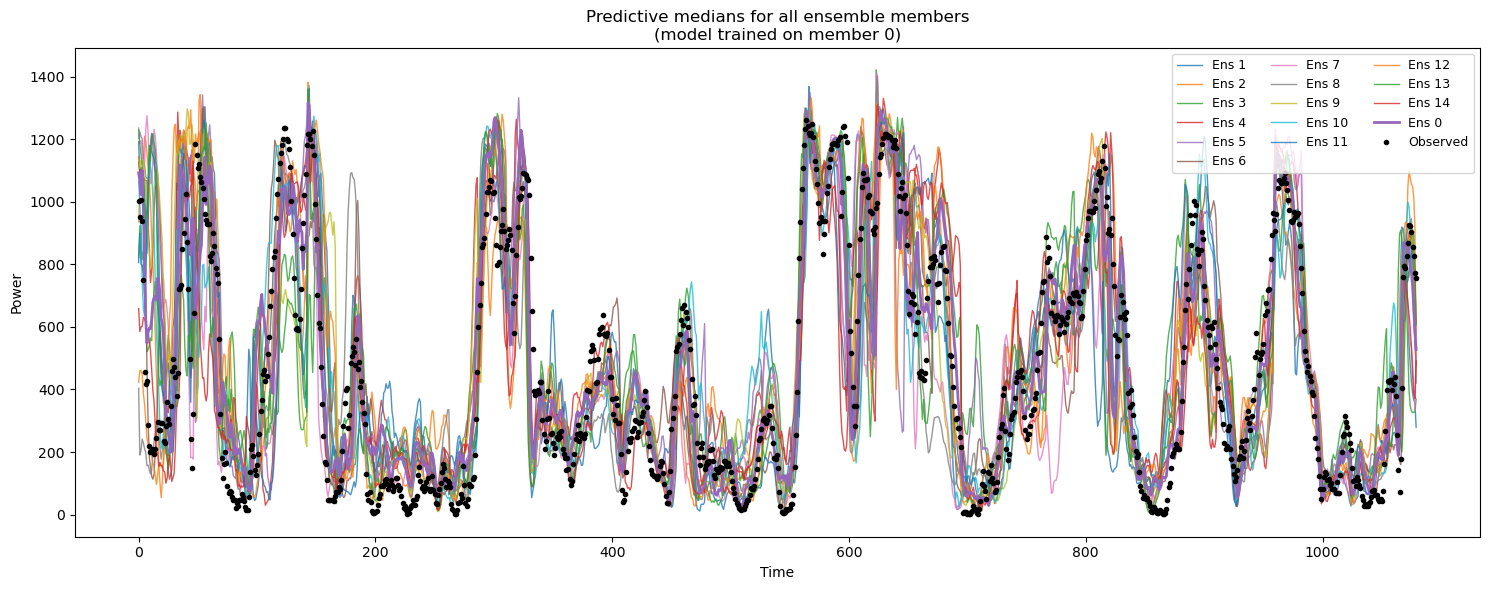

In [52]:
if model_cfg.backend == "torch" and len(data["X_train"].shape) == 4:
    evaluate_and_plot_qr_ensemble_medians(
        model=model,
        data=data,
        quantiles=quantiles,
        n_members=15,
        n_plot=1080,
    )

Compare learned weights for aggregation and max capacity of parks


In [53]:
import torch

if model_cfg.backend == "numpyro":
    agg_logits = samples["agg_logits"].mean(0)
elif model_cfg.backend == "torch":
    agg_logits = torch.softmax(checkpoint["model_state_dict"]["agg_logits"], dim=0)

print(
    "Max capacity wind parks: ",
    torch.softmax(torch.tensor(data["sites_meta"]), 0).reshape([-1]),
)
print("Learned weightings wind parks: ", agg_logits)

Max capacity wind parks:  tensor([0.4298, 0.0285, 0.0422, 0.0124, 0.0263, 0.0267, 0.0672, 0.0492, 0.0124,
        0.0115, 0.0143, 0.0759, 0.0121, 0.1461, 0.0190, 0.0153, 0.0112],
       dtype=torch.float64)
Learned weightings wind parks:  tensor([0.0622, 0.1232, 0.1332, 0.0004, 0.0365, 0.0433, 0.1182, 0.1500, 0.0004,
        0.0161, 0.0036, 0.1514, 0.0004, 0.0933, 0.0519, 0.0144, 0.0016])


Max capacity wind parks:  tensor([0.4298, 0.0285, 0.0422, 0.0124, 0.0263, 0.0267, 0.0672, 0.0492, 0.0124,
        0.0115, 0.0143, 0.0759, 0.0121, 0.1461, 0.0190, 0.0153, 0.0112],
       dtype=torch.float64)
Learned weightings wind parks:  tensor([0.0622, 0.1232, 0.1332, 0.0004, 0.0365, 0.0433, 0.1182, 0.1500, 0.0004,
        0.0161, 0.0036, 0.1514, 0.0004, 0.0933, 0.0519, 0.0144, 0.0016])


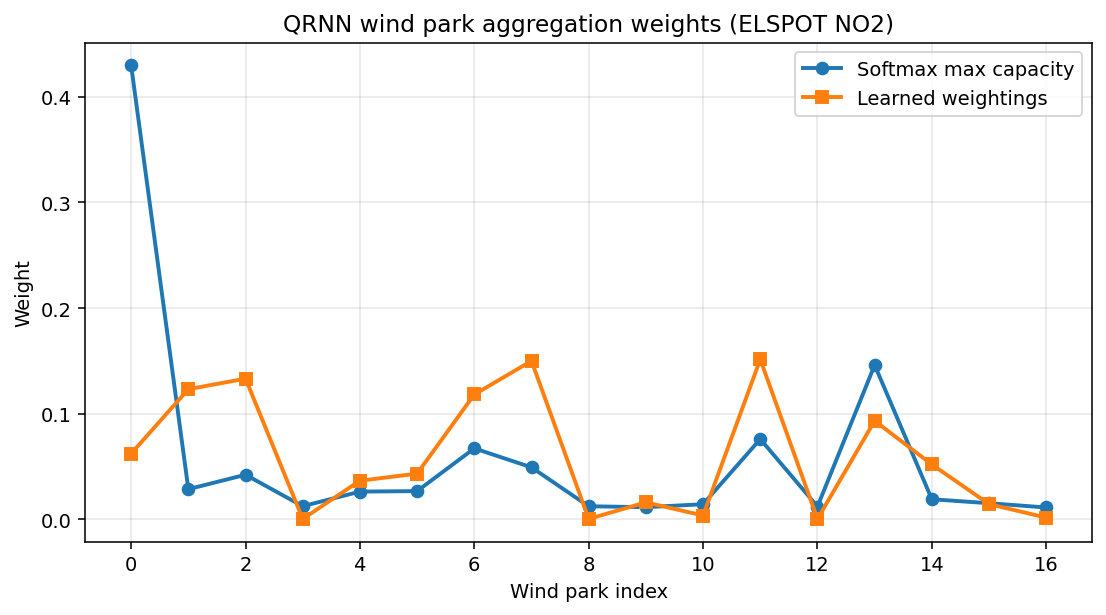

In [54]:
softmax_caps = torch.softmax(torch.tensor(data["sites_meta"]), 0).numpy()
learned_weights = (
    samples["agg_logits"].mean(0)
    if model_cfg.backend == "numpyro"
    else torch.softmax(checkpoint["model_state_dict"]["agg_logits"], dim=0)
)

print(
    "Max capacity wind parks: ",
    torch.softmax(torch.tensor(data["sites_meta"]), 0).reshape([-1]),
)
print("Learned weightings wind parks: ", learned_weights)
x = np.arange(len(softmax_caps))

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=140)

ax.plot(
    x,
    softmax_caps,
    marker="o",
    lw=2,
    label="Softmax max capacity",
)

ax.plot(
    x,
    learned_weights,
    marker="s",
    lw=2,
    label="Learned weightings",
)

ax.set_xlabel("Wind park index")
ax.set_ylabel("Weight")
ax.set_title(
    f"{model_name_for_title} wind park aggregation weights ({model_cfg.data.bid_zone})"
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(
    f"../plots/agg_weights_{model_name_for_title}_{data_cfg.dataset}_{model_cfg.data.bid_zone}.pdf"
)

In [55]:
import copy

data_copy = copy.deepcopy(data)

In [56]:
# # TODO: only for member 0
# window_size = 1080

# metrics_train_list = []


# for start in range(0, length, window_size):
#     end = min(start + window_size, length)
#     print(start)
#     end = start + window_size

#     data["X_train"] = data_copy["X_train"][start:end]
#     data["Y_train_gen"] = data_copy["Y_train_gen"][start:end]
#     if model_cfg.backend == "numpyro":
#         (
#             metrics_train,
#             y_pred_train,
#             predictive_train,
#             median_train,
#             percentiles_train,
#             hdis_train,
#         ) = evaluate_numpyro_on_train_set(
#             model, checkpoint["samples"], checkpoint["rng_key_predict"], data, model_cfg
#         )
#     else:
#         model, checkpoint = load_torch_model(file_name=file_name, quantiles=quantiles)
#         if model_cfg.params.quantiles is None:
#             if model_cfg.params.num_quantiles is not None:
#                 quantiles = torch.linspace(0, 1, model_cfg.params.num_quantiles)
#             else:
#                 quantiles = torch.linspace(0, 1, 51)
#         else:
#             quantiles = torch.tensor(model_cfg.params.quantiles)
#         metrics_train, _ = evaluate_model(model, data, quantiles, model_cfg)
#         metrics_train["rmse_median"] = metrics_train["rmse_median_train"]
#         metrics_train["crps"] = metrics_train["crps_train"]

#     metrics_train_list.append(metrics_train)
# rmse_vals = np.array([d["rmse_median"] for d in metrics_train_list])
# crps_vals = np.array([d["crps"] for d in metrics_train_list])


# def summarize(x):
#     return {
#         "mean": np.mean(x),
#         "std": np.std(x),
#         "min": np.min(x),
#         "max": np.max(x),
#         "range": np.max(x) - np.min(x),
#     }


# print("RMSE:", summarize(rmse_vals))
# print("CRPS:", summarize(crps_vals))

# plt.figure(figsize=(8, 4))
# plt.plot(rmse_vals, label="RMSE")
# plt.plot(crps_vals, label="CRPS")
# # TODO: shade for used time period, add pots for points
# plt.axvline(8, color="black", lw=1, linestyle="--", label="next year reference line")
# plt.xlabel("1.5 month windows")
# plt.ylabel("Value")
# plt.legend()
# plt.title(
#     f"RMSE and CRPS across windows of 1.5 months {model_name_for_title} ({model_cfg.data.bid_zone})"
# )
# # plt.savefig(
# #     f"../plots/metrics_windows_{model_name_for_title}_{model_cfg.data.bid_zone}_{data_cfg.dataset}.pdf"
# # )
# plt.show()

1080
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-26-57_nowcast_gen_ELSPOT_NO2.pt
  Model class: WindPowerQuantile_weighted
Choose member 0
Choose member 0
     rmse_median_train: tensor(193.8555)

   crps_train: tensor(101.8305)

   coverage_025_975_train: tensor(0.7824)

   coverage_0_50_train: tensor(0.3981)
1080
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-26-57_nowcast_gen_ELSPOT_NO2.pt
  Model class: WindPowerQuantile_weighted
Choose member 0
Choose member 0
     rmse_median_train: tensor(134.4781)

   crps_train: tensor(71.4943)

   coverage_025_975_train: tensor(0.8880)

   coverage_0_50_train: tensor(0.4889)
1080
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-26-57_nowcast_gen_ELSPOT_NO2.pt
  Model class: WindPowerQuantile_weighted
Choose member 0
Choose member 0
     rmse_median_train: tensor(149.5952)

   crps_train: tensor(77.1972)

   coverage_025_975_train: tensor(0.8056)

   coverage_0_50_train: tensor(0.3870)
1080
Loaded model: WindPowerQuant

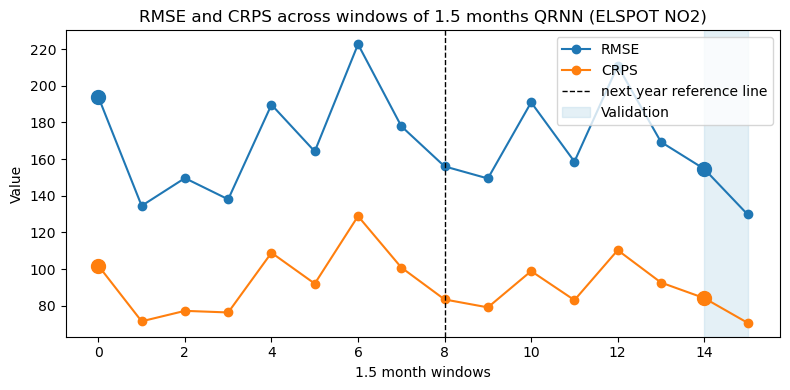

In [60]:
window_size = 1080  # 1.5 months

metrics_train_list = []
window_labels = []
for s in ["train", "test"]:
    length = len(data_copy[f"X_{s}"])
    for start in range(0, length, window_size):
        end = min(start + window_size, length)
        print(end - start)

        data["X_train"] = data_copy[f"X_{s}"][start:end]
        data["Y_train_gen"] = data_copy[f"Y_{s}_gen"][start:end]

        if model_cfg.backend == "numpyro":
            (
                metrics_train,
                y_pred_train,
                predictive_train,
                median_train,
                percentiles_train,
                hdis_train,
            ) = evaluate_numpyro_on_train_set(
                model,
                checkpoint["samples"],
                checkpoint["rng_key_predict"],
                data,
                model_cfg,
            )
        else:
            model, checkpoint = load_torch_model(
                file_name=file_name, quantiles=quantiles
            )
            if model_cfg.params.quantiles is None:
                if model_cfg.params.num_quantiles is not None:
                    quantiles = torch.linspace(0, 1, model_cfg.params.num_quantiles)
                else:
                    quantiles = torch.linspace(0, 1, 51)
            else:
                quantiles = torch.tensor(model_cfg.params.quantiles)

            metrics_train, _ = evaluate_model(model, data, quantiles, model_cfg)
            metrics_train["rmse_median"] = metrics_train["rmse_median_train"]
            metrics_train["crps"] = metrics_train["crps_train"]

        metrics_train_list.append(metrics_train)
        window_labels.append(f"{start}-{end}")

# plotting
rmse_vals = np.array([d["rmse_median"] for d in metrics_train_list])
crps_vals = np.array([d["crps"] for d in metrics_train_list])


def summarize(x):
    return {
        "mean": np.mean(x),
        "std": np.std(x),
        "min": np.min(x),
        "max": np.max(x),
        "range": np.max(x) - np.min(x),
    }


print("RMSE:", summarize(rmse_vals))
print("CRPS:", summarize(crps_vals))

plt.figure(figsize=(8, 4))

default_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
x = np.arange(len(rmse_vals))

plt.plot(rmse_vals, marker="o", label="RMSE")
plt.scatter(x[0], rmse_vals[0], s=100, zorder=3, color=default_colors[0])
plt.scatter(x[-2], rmse_vals[-2], s=100, zorder=3, color=default_colors[0])

plt.plot(crps_vals, marker="o", label="CRPS")
plt.scatter(x[0], crps_vals[0], s=100, zorder=3, color=default_colors[1])
plt.scatter(x[-2], crps_vals[-2], s=100, zorder=3, color=default_colors[1])

plt.axvline(8, color="black", lw=1, linestyle="--", label="next year reference line")
if len(rmse_vals) > 16:
    plt.axvline(
        16, color="black", lw=1, linestyle="--", label="next year reference line"
    )

plt.axvspan(x[-2], x[-1], color="#A6CEE3", alpha=0.3, label="Validation")
plt.xlabel("1.5 month windows")
plt.ylabel("Value")
plt.legend()
plt.title(
    f"RMSE and CRPS across windows of 1.5 months {model_name_for_title} ({model_cfg.data.bid_zone})"
)
plt.tight_layout()
plt.savefig(
    f"../plots/metrics_windows_{model_name_for_title}_{model_cfg.data.bid_zone}_{data_cfg.dataset}.pdf"
)

In [58]:
print("Worst RMSE window:", np.argmax(rmse_vals))
print("Worst CRPS window:", np.argmax(crps_vals))

print("Best RMSE window:", np.argmin(rmse_vals))
print("Best CRPS window:", np.argmin(crps_vals))

Worst RMSE window: 6
Worst CRPS window: 6
Best RMSE window: 15
Best CRPS window: 15


In [59]:
idx_rmse = np.argmin(np.abs(rmse_vals - np.mean(rmse_vals)))
idx_crps = np.argmin(np.abs(crps_vals - np.mean(crps_vals)))
print(idx_rmse, idx_crps)

13 5
